In [1]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import SimpleITK as sitk
from src.data.io_utils import read_tif_image, convert_image_to_array, save_array
from src.models.swin_unetr_monai import SwinUNETR3D
from src.inference.predict import load_model

/home/mima/anaconda3/envs/segmentation_cfos/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-07-30 13:38:31.317696: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
image_path = Path("/mnt/x/donnees/images_test/images/image.tif")
mask_path = Path("/mnt/x/donnees/images_test/masks/mask.tif")
output_dir = Path("/mnt/x/donnees/images_test/mask_predit")
output_dir.mkdir(parents=True, exist_ok=True)

In [3]:
model_path = project_root / "outputs" / "swin_3class_slices40_focal" / "checkpoints" / "best_model.pth"

print(f"Image existe: {image_path.exists()}")
print(f"Mask existe: {mask_path.exists()}")
print(f"Modèle existe: {model_path.exists()}")

Image existe: True
Mask existe: True
Modèle existe: True


In [4]:
print("Chargement de l'image...")
image_sitk = read_tif_image(str(image_path))
image = convert_image_to_array(image_sitk)  # shape (Z, Y, X)

mask_sitk = read_tif_image(str(mask_path))
mask_true = convert_image_to_array(mask_sitk)  # shape (Z, Y, X)

print(f"Image shape: {image.shape}")
print(f"Mask shape: {mask_true.shape}")

Chargement de l'image...
Image shape: (180, 350, 276)
Mask shape: (180, 350, 276)


In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Modèle: {model_path}")
print(f"Device: {device}")
checkpoint = torch.load(model_path, map_location=device)


model = SwinUNETR3D(
    in_channels=1,
    out_channels=3,  
    feature_size=48,
    drop_rate=0.0,
    attn_drop_rate=0.0,
    use_checkpoint=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("✅ Modèle chargé!")
print(f"   Époque: {checkpoint.get('epoch', 'N/A')}")
print(f"   Meilleur score: {checkpoint.get('best_score', 'N/A')}")

Chargement du modèle...
Modèle: /mnt/x/segmentation_cfos/outputs/swin_3class_slices40_focal/checkpoints/best_model.pth
Device: cuda
✅ Modèle chargé!
   Époque: 12
   Meilleur score: 0.6244600236415863


In [6]:
def pad_to_multiple(image, patch_size=64):
    """Pad l'image pour que les dimensions soient multiples de patch_size"""
    current_shape = image.shape
    new_shape = []
    pads = []
    
    for dim in range(3):
        remainder = current_shape[dim] % patch_size
        if remainder == 0:
            new_shape.append(current_shape[dim])
            pads.append(0)
        else:
            pad = patch_size - remainder
            new_shape.append(current_shape[dim] + pad)
            pads.append(pad)
    
    new_shape = tuple(new_shape)
    pad_width = [(0, pads[0]), (0, pads[1]), (0, pads[2])]
    padded_image = np.pad(image, pad_width=pad_width, mode='constant', constant_values=0)
    
    return padded_image, pads, new_shape


In [7]:
def extract_patches_3d(image, patch_size=64):
    """Extrait les patches de l'image"""
    patches = []
    coords = []
    
    z_steps = image.shape[0] // patch_size
    y_steps = image.shape[1] // patch_size
    x_steps = image.shape[2] // patch_size
    
    for z in range(z_steps):
        for y in range(y_steps):
            for x in range(x_steps):
                z_start = z * patch_size
                y_start = y * patch_size
                x_start = x * patch_size
                
                patch = image[
                    z_start:z_start + patch_size,
                    y_start:y_start + patch_size,
                    x_start:x_start + patch_size
                ]
                patches.append(patch)
                coords.append((z_start, y_start, x_start))
    
    return patches, coords

In [8]:
def reconstruct_from_patches(patches, coords, original_shape, patch_size=64):
    """Reconstruit l'image à partir des patches"""
    reconstructed = np.zeros(original_shape, dtype=np.float32)
    weights = np.zeros(original_shape, dtype=np.float32)
    
    for patch, (z_start, y_start, x_start) in zip(patches, coords):
        reconstructed[
            z_start:z_start + patch_size,
            y_start:y_start + patch_size,
            x_start:x_start + patch_size
        ] += patch
        weights[
            z_start:z_start + patch_size,
            y_start:y_start + patch_size,
            x_start:x_start + patch_size
        ] += 1
    
    weights[weights == 0] = 1
    reconstructed = reconstructed / weights
    
    return reconstructed

In [9]:
PATCH_SIZE = 64

print("Préparation de l'image...")
padded_image, pads, padded_shape = pad_to_multiple(image, PATCH_SIZE)
print(f"Image originale: {image.shape}")
print(f"Image paddée: {padded_shape}")
print(f"Padding ajouté: {pads}")

patches, coords = extract_patches_3d(padded_image, PATCH_SIZE)
print(f"Nombre de patches: {len(patches)}")
print(f"Taille d'un patch: {patches[0].shape}")

Préparation de l'image...
Image originale: (180, 350, 276)
Image paddée: (192, 384, 320)
Padding ajouté: [12, 34, 44]
Nombre de patches: 90
Taille d'un patch: (64, 64, 64)


In [10]:
print("Prédiction en cours...")
model.eval()
predictions = []

with torch.no_grad():
    for i, patch in enumerate(tqdm(patches, desc="Patches")):
        # Normaliser le patch
        patch_norm = patch.astype(np.float32)
        min_val = patch_norm.min()
        max_val = patch_norm.max()
        if max_val - min_val > 0:
            patch_norm = (patch_norm - min_val) / (max_val - min_val)
        else:
            patch_norm = np.zeros_like(patch_norm)
        
        # Ajouter les dimensions
        patch_tensor = torch.from_numpy(patch_norm).float()
        patch_tensor = patch_tensor.unsqueeze(0).unsqueeze(0).to(device)  # (1, 1, Z, Y, X)
        
        # Prédiction
        pred = model(patch_tensor)
        pred = torch.softmax(pred, dim=1)
        pred = pred.cpu().numpy().squeeze()
        
        # Prendre la classe avec la plus haute probabilité
        pred_class = np.argmax(pred, axis=0).astype(np.float32)
        predictions.append(pred_class)

Prédiction en cours...


Patches: 100%|█████████████████████████████████████████████████████████████| 90/90 [00:24<00:00,  3.69it/s]


In [11]:
print("Reconstruction de l'image...")
reconstructed = reconstruct_from_patches(predictions, coords, padded_shape, PATCH_SIZE)

# Enlever le padding
if pads[0] > 0:
    reconstructed = reconstructed[:-pads[0], :, :]
if pads[1] > 0:
    reconstructed = reconstructed[:, :-pads[1], :]
if pads[2] > 0:
    reconstructed = reconstructed[:, :, :-pads[2]]

print(f"Image reconstruite: {reconstructed.shape}")


print("Sauvegarde du mask prédit...")
output_path = output_dir / "predicted_mask.tif"
reconstructed_uint8 = (reconstructed * 255).astype(np.uint8)
save_array(reconstructed_uint8, str(output_path))
print(f"✅ Mask sauvegardé: {output_path}")


Reconstruction de l'image...
Image reconstruite: (180, 350, 276)
Sauvegarde du mask prédit...
✅ Mask sauvegardé: /mnt/x/donnees/images_test/mask_predit/predicted_mask.tif


Visualisation des résultats...
Vrais neurones: 67828
Neurones prédits: 38940
Ratio: 0.57


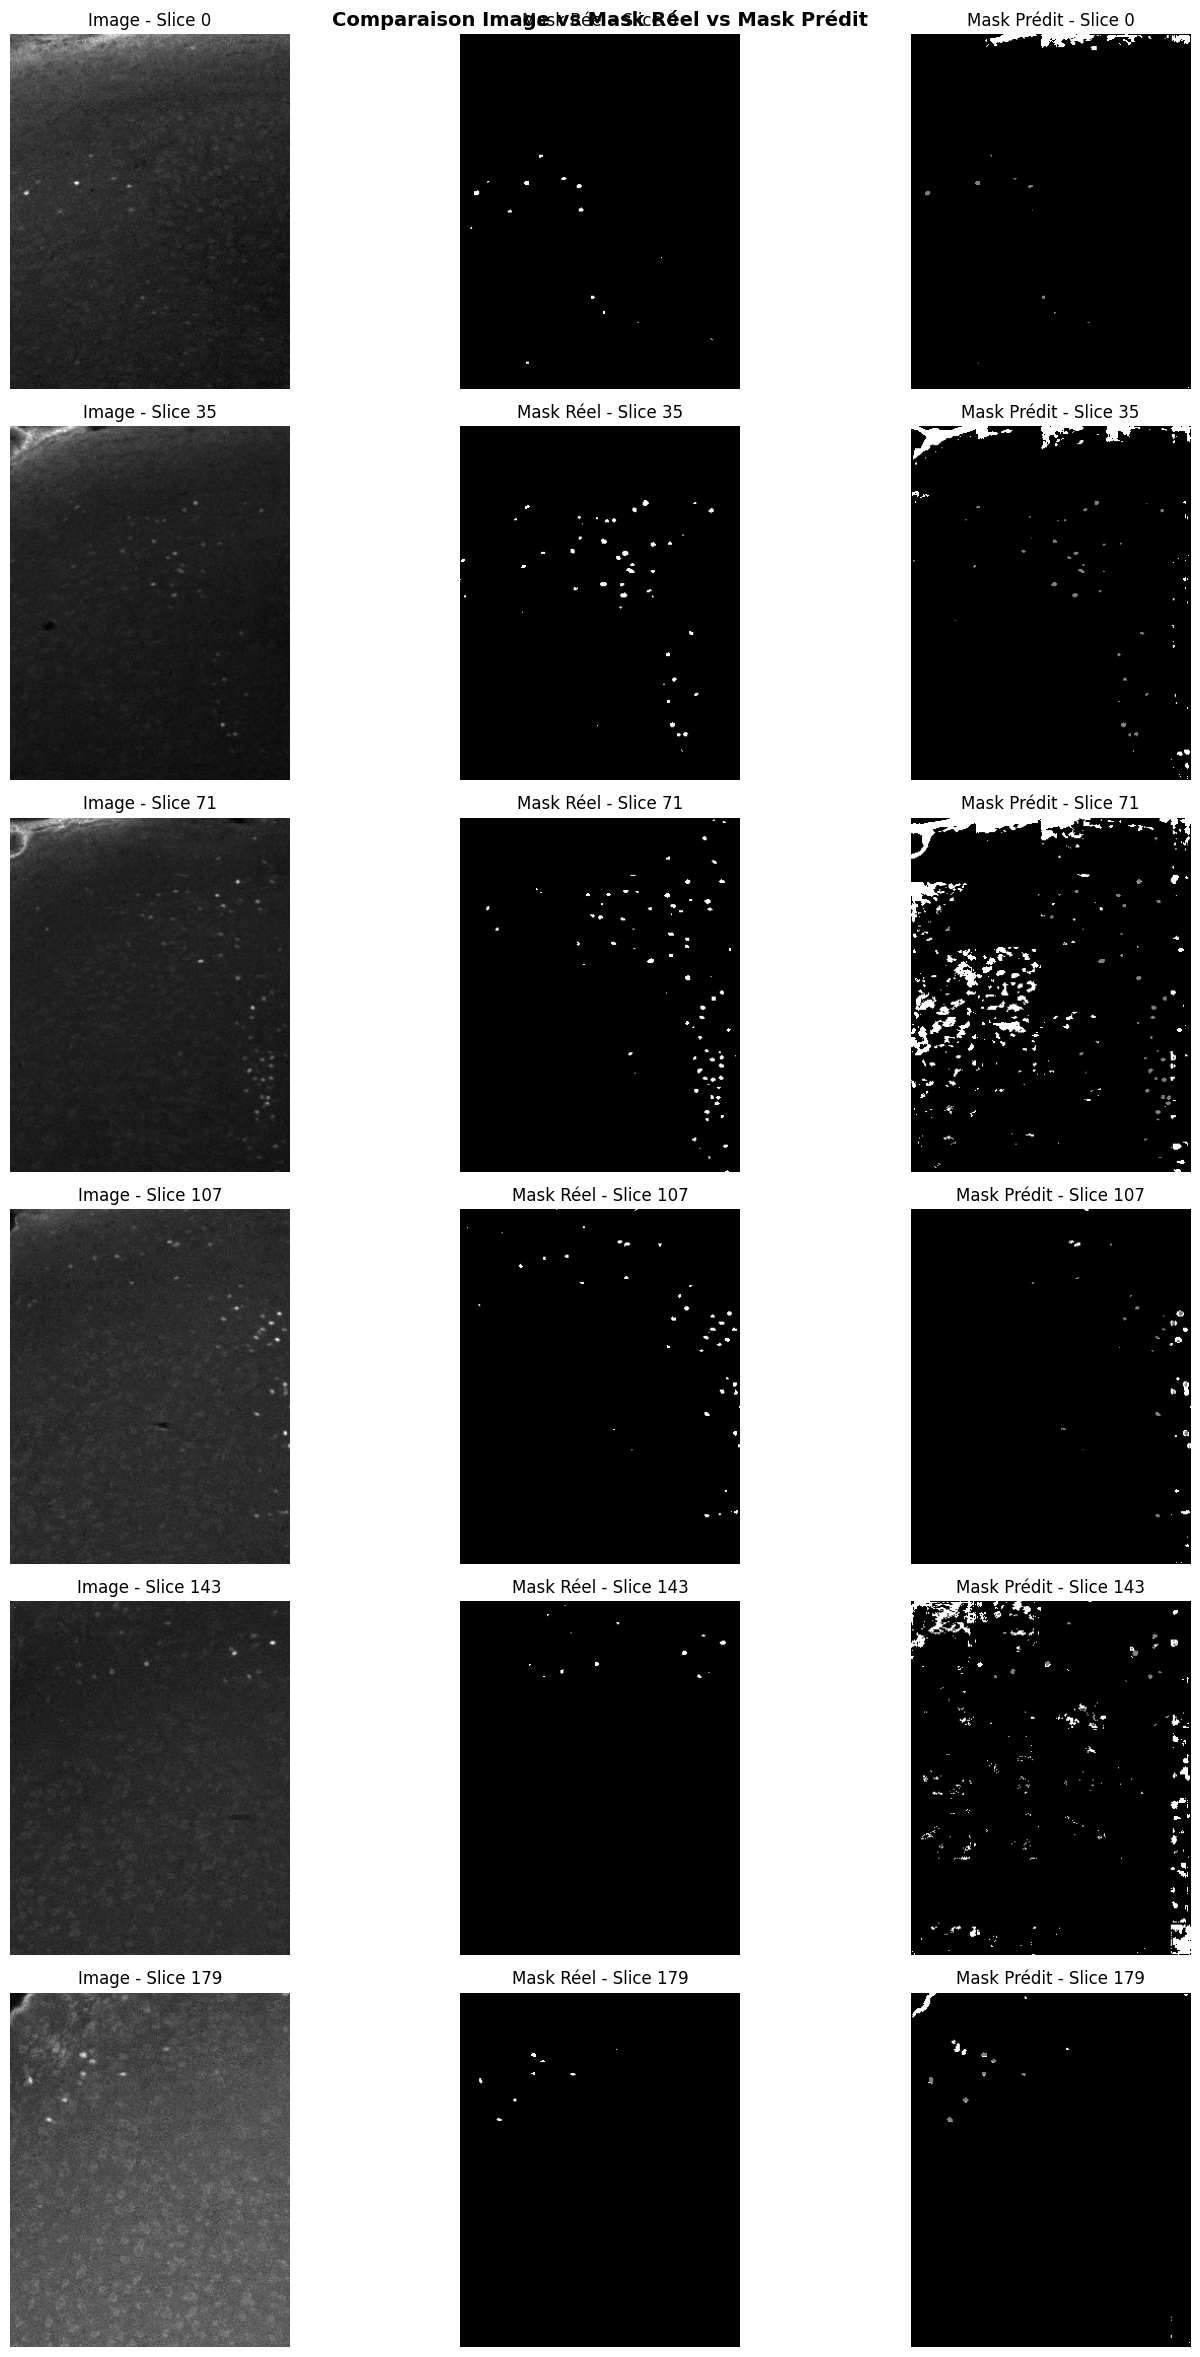

In [12]:
print("Visualisation des résultats...")

pred_neurons = (reconstructed == 1).sum()
true_neurons = (mask_true == 1).sum()

print(f"Vrais neurones: {true_neurons}")
print(f"Neurones prédits: {pred_neurons}")
print(f"Ratio: {pred_neurons / true_neurons if true_neurons > 0 else 0:.2f}")
num_slices = 6
total_z = reconstructed.shape[0]
slice_indices = np.linspace(0, total_z - 1, num_slices, dtype=int)

fig, axes = plt.subplots(num_slices, 3, figsize=(15, 4*num_slices))

for i, z_idx in enumerate(slice_indices):
    img_slice = image[z_idx, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    axes[i, 0].imshow(img_slice, cmap='gray')
    axes[i, 0].set_title(f'Image - Slice {z_idx}')
    axes[i, 0].axis('off')
    
    true_slice = mask_true[z_idx, :, :]
    axes[i, 1].imshow(true_slice, cmap='gray')
    axes[i, 1].set_title(f'Mask Réel - Slice {z_idx}')
    axes[i, 1].axis('off')
    
    pred_slice = reconstructed[z_idx, :, :]
    axes[i, 2].imshow(pred_slice, cmap='gray')
    axes[i, 2].set_title(f'Mask Prédit - Slice {z_idx}')
    axes[i, 2].axis('off')

plt.suptitle('Comparaison Image vs Mask Réel vs Mask Prédit', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Superposition Image + Mask Prédit...


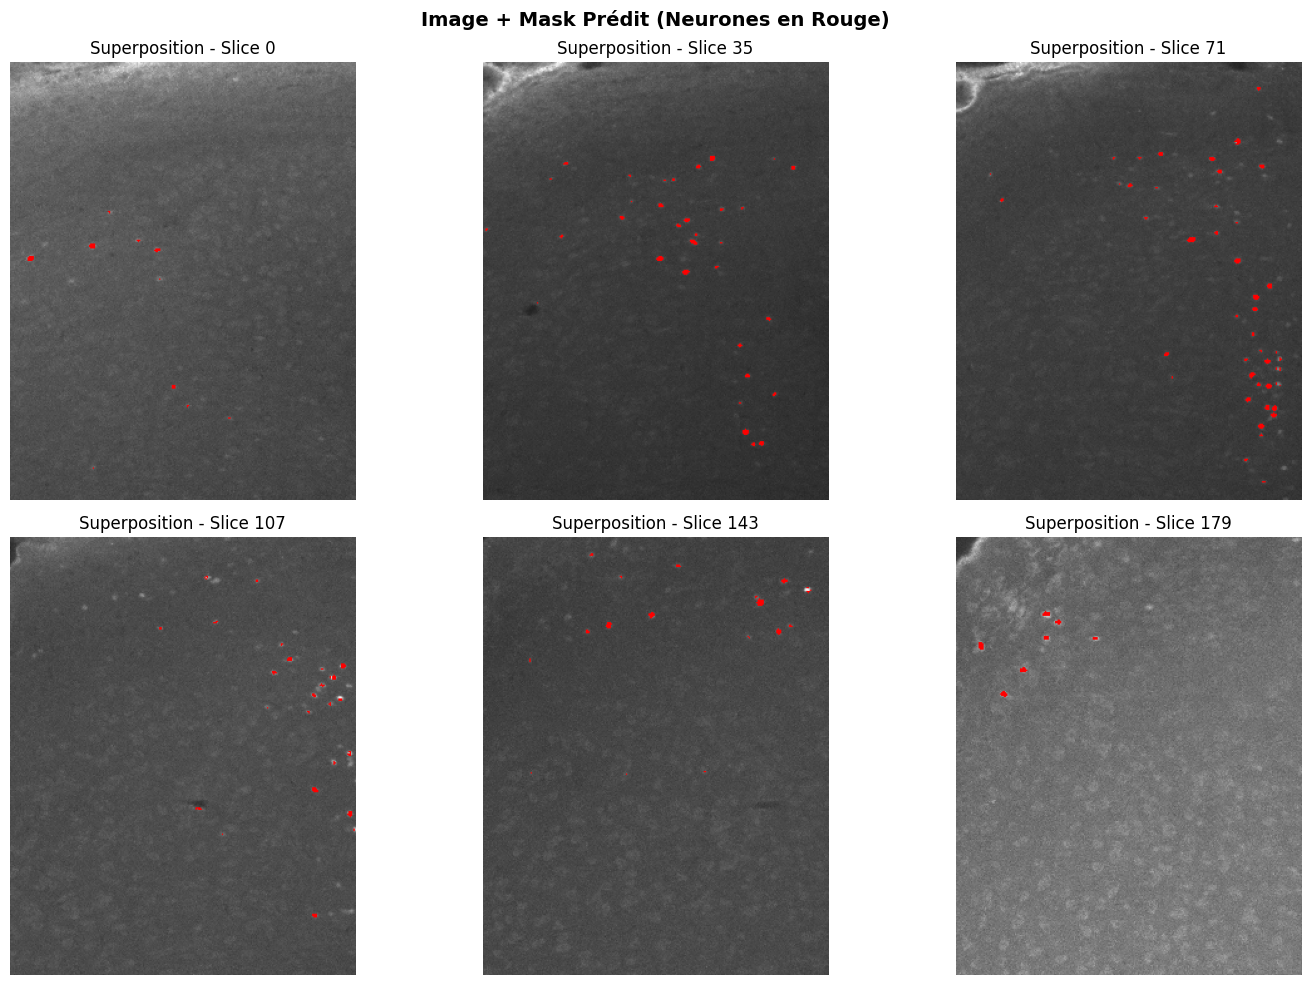

In [13]:
print("Superposition Image + Mask Prédit...")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
random_slices = np.linspace(0, total_z - 1, 6, dtype=int)

for i, z_idx in enumerate(random_slices):
    img_slice = image[z_idx, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    
    pred_slice = reconstructed[z_idx, :, :]
    
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[pred_slice == 1, 0] = 1
    overlay[pred_slice == 1, 1] = 0
    overlay[pred_slice == 1, 2] = 0
    
    row = i // 3
    col = i % 3
    axes[row, col].imshow(overlay)
    axes[row, col].set_title(f'Superposition - Slice {z_idx}')
    axes[row, col].axis('off')

plt.suptitle('Image + Mask Prédit (Neurones en Rouge)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [14]:
print("\n" + "=" * 60)
print("STATISTIQUES FINALES")
print("=" * 60)
print(f"Taille de l'image: {image.shape}")
print(f"Taille du mask prédit: {reconstructed.shape}")
print()
print(f"Vrais neurones: {true_neurons}")
print(f"Neurones prédits: {pred_neurons}")
print(f"Ratio: {pred_neurons / true_neurons if true_neurons > 0 else 0:.2f}")
print()
print(f"Padding ajouté: {pads}")
print(f"Patches créés: {len(patches)}")
print(f"Mask sauvegardé: {output_path}")




STATISTIQUES FINALES
Taille de l'image: (180, 350, 276)
Taille du mask prédit: (180, 350, 276)

Vrais neurones: 67828
Neurones prédits: 38940
Ratio: 0.57

Padding ajouté: [12, 34, 44]
Patches créés: 90
Mask sauvegardé: /mnt/x/donnees/images_test/mask_predit/predicted_mask.tif
